# 02 · From eigenimages to a region of interest

Notebook 01 showed that the leading principal components are not
necessarily the ones that separate the diagnoses. Here we:

1. compute the first $k = 15$ PCs inside the brain mask;
2. run a **Welch ANOVA** on each PC score across CN / MCI / AD (Welch
   because the group variances differ), with a Bonferroni correction
   ($\alpha = 0.01$);
3. combine the eigenimages of the most significant PCs, weighted by their
   $F$ statistic, into a **map of where the groups differ**;
4. threshold, smooth and clean that map into one or more connected
   **regions of interest (ROI)**.

The ROI is later used as the mask for radiomics features (notebooks 04–05).
This notebook is descriptive and uses every subject of one view. In the
classification notebooks the same procedure is fitted on the training split
only, to avoid information leakage.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from adni_tau.data import ImageLoader
from adni_tau.paths import save_figure, save_table
from adni_tau.roi import pca_roi

plt.rcParams["figure.dpi"] = 90
VIEWS = ["axial", "coronal", "sagittal"]
ORDER = ["CN", "MCI", "AD"]

loader = ImageLoader(views=VIEWS)
data = {view: loader.load_view(view) for view in VIEWS}
roi_by_view = {view: pca_roi(d["X"], d["classes"], d["shape"]) for view, d in data.items()}

## 1. Which components differ between groups?

In [2]:
VIEW = "coronal"
res = roi_by_view[VIEW]
tests = res.group_tests.copy()
tests["explained_variance"] = [res.explained_variance[int(pc[2:]) - 1] for pc in tests["pc"]]
save_table(tests, "02_welch_anova_coronal")
tests.round(4)

,pc,test,F,p_value,effect_size,p_adj,reject_null,explained_variance
0,PC4,welch,71.9581,0.0000,0.1447,0.0000,True,0.0211
1,PC2,welch,37.2813,0.0000,0.0599,0.0000,True,0.0626
2,PC3,welch,32.9443,0.0000,0.0800,0.0000,True,0.0282
3,PC10,welch,8.3028,0.0003,0.0144,0.0047,True,0.0080
4,PC14,welch,5.2494,0.0058,0.0109,0.0869,False,0.0060
5,PC8,welch,4.3538,0.0137,0.0080,0.2058,False,0.0103
6,PC7,welch,2.9998,0.0514,0.0055,0.7704,False,0.0126
7,PC13,welch,1.7696,0.1724,0.0034,1.0000,False,0.0065
8,PC11,welch,1.6638,0.1912,0.0030,1.0000,False,0.0072
9,PC15,welch,0.7982,0.4511,0.0014,1.0000,False,0.0055


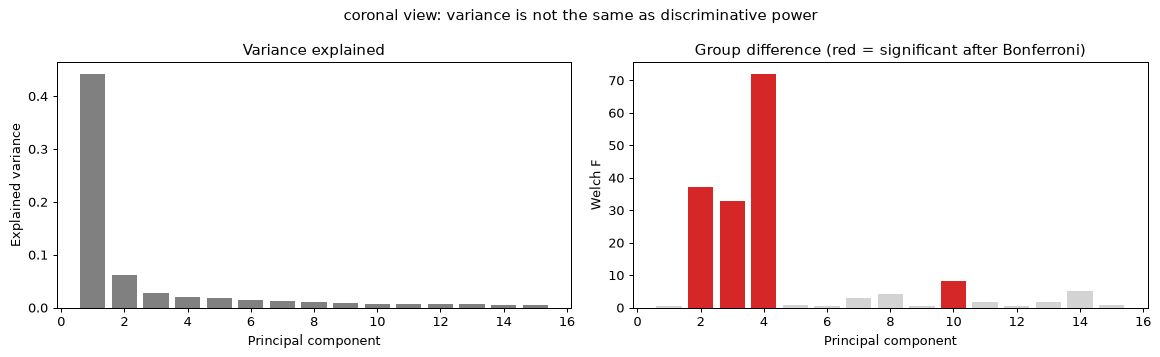

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = sorted(tests["pc"], key=lambda s: int(s[2:]))
t = tests.set_index("pc").loc[order]
axes[0].bar(range(1, len(t) + 1), t["explained_variance"], color="gray")
axes[0].set(xlabel="Principal component", ylabel="Explained variance", title="Variance explained")
axes[1].bar(range(1, len(t) + 1), t["F"], color=np.where(t["reject_null"], "tab:red", "lightgray"))
axes[1].set(xlabel="Principal component", ylabel="Welch F", title="Group difference (red = significant after Bonferroni)")
fig.suptitle(f"{VIEW} view: variance is not the same as discriminative power")
fig.tight_layout()
save_figure(fig, "02_variance_vs_F")

Components that explain a lot of variance (e.g. PC1) are not always the
ones that differ between diagnostic groups, and several small-variance
components are highly significant.

## 2. Eigenimages and group means of the selected components

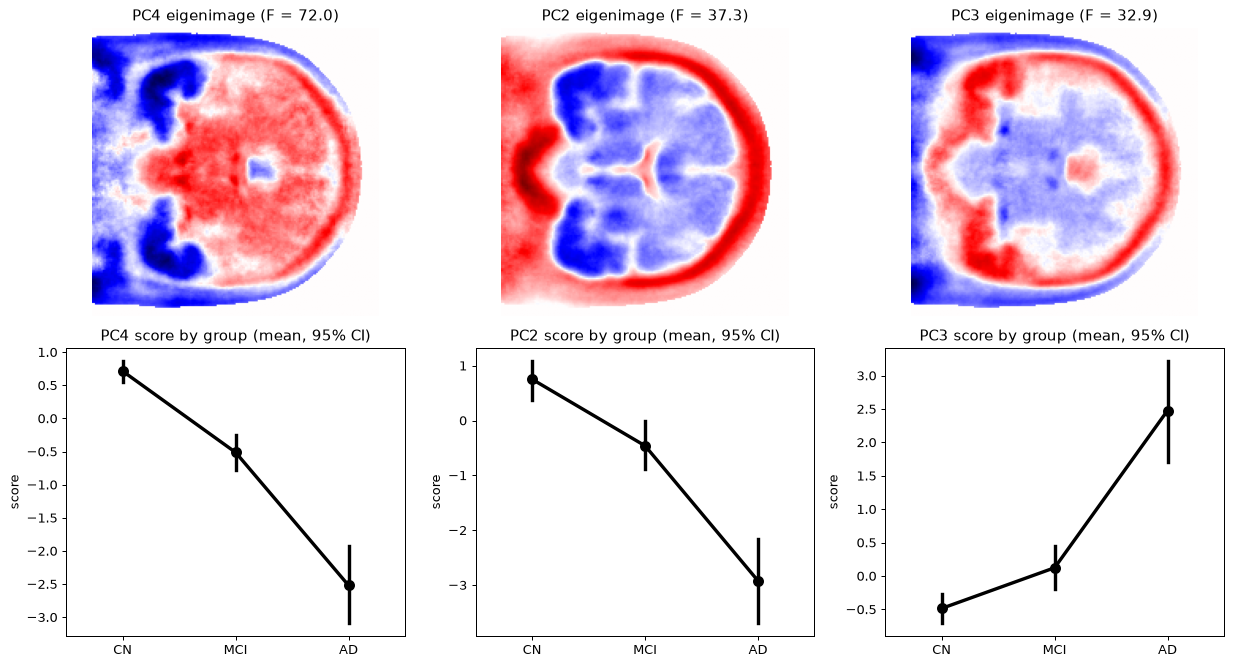

In [4]:
sel = res.selected_pcs
fig, axes = plt.subplots(2, len(sel), figsize=(4.6 * len(sel), 7.5), squeeze=False)
for j, pc in enumerate(sel):
    lim = np.abs(res.eigenimages[pc]).max()
    axes[0, j].imshow(res.eigenimages[pc], cmap="seismic", vmin=-lim, vmax=lim)
    F = tests.set_index("pc").loc[f"PC{pc + 1}", "F"]
    axes[0, j].set_title(f"PC{pc + 1} eigenimage (F = {F:.1f})")
    axes[0, j].axis("off")
    sns.pointplot(x=data[VIEW]["classes"], y=res.scores[:, pc], order=ORDER, errorbar=("ci", 95), ax=axes[1, j], color="k")
    axes[1, j].set(title=f"PC{pc + 1} score by group (mean, 95% CI)", ylabel="score")
fig.tight_layout()
save_figure(fig, "02_selected_pcs")

The selected components show a **monotone trend CN → MCI → AD**: MCI lies
between the two extremes, consistent with a disease continuum.

## 3. Building the ROI

The weighted map $\sum_{j} F_j \, |v_j|$ (sum over the selected PCs) is
smoothed with a Gaussian filter ($\sigma = 1$). Its top 10% of pixels are
cleaned with a morphological opening and closing ($5\times5$), and connected
components whose mean weight is above the 95th percentile are kept.
Components touching the image border are discarded: in these slices they
fall on the neck or the skull edge, not on brain tissue.

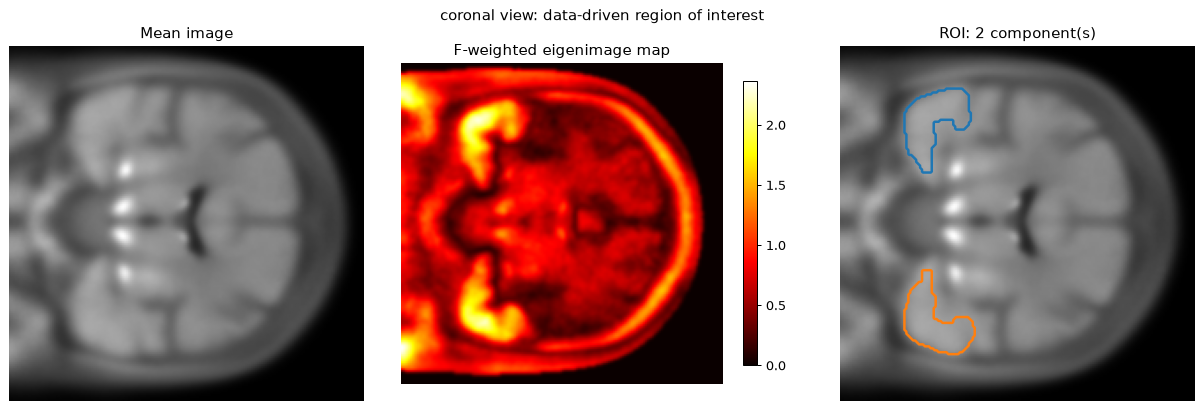

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(data[VIEW]["X"].mean(axis=0).reshape(res.shape), cmap="gray")
axes[0].set_title("Mean image")
im = axes[1].imshow(res.weight_map, cmap="hot")
axes[1].set_title("F-weighted eigenimage map")
fig.colorbar(im, ax=axes[1], shrink=0.8)
axes[2].imshow(data[VIEW]["X"].mean(axis=0).reshape(res.shape), cmap="gray")
for i, comp in enumerate(res.components):
    axes[2].contour(comp, levels=[0.5], colors=[plt.cm.tab10(i)], linewidths=2)
axes[2].set_title(f"ROI: {len(res.components)} component(s)")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"{VIEW} view: data-driven region of interest")
fig.tight_layout()
save_figure(fig, "02_roi_coronal")

## 4. ROIs in all three views

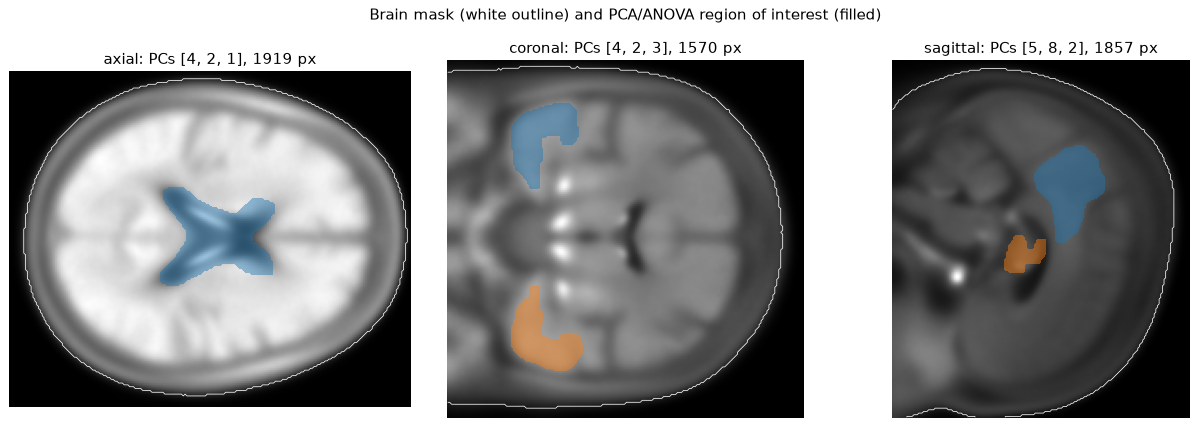

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, view in zip(axes, VIEWS):
    r = roi_by_view[view]
    ax.imshow(data[view]["X"].mean(axis=0).reshape(r.shape), cmap="gray")
    ax.contour(r.brain_mask, levels=[0.5], colors="white", linewidths=0.6)
    for i, comp in enumerate(r.components):
        ax.contourf(comp, levels=[0.5, 1.5], colors=[plt.cm.tab10(i)], alpha=0.45)
    ax.set_title(f"{view}: PCs {[p + 1 for p in r.selected_pcs]}, {r.roi.sum()} px")
    ax.axis("off")
fig.suptitle("Brain mask (white outline) and PCA/ANOVA region of interest (filled)")
fig.tight_layout()
save_figure(fig, "02_roi_all_views")

**Interpretation.** The ROIs land on anatomically meaningful structures:

- **coronal**: bilateral medial/inferior temporal lobes, the earliest
  neocortical sites of tau accumulation in Alzheimer's disease (Braak
  stages III-IV);
- **sagittal**: posterior parietal cortex, involved at later stages;
- **axial**: the lateral ventricles. This is not tau uptake but a proxy for
  **atrophy**: ventricles enlarge as the surrounding tissue shrinks.

The method is purely data-driven: no atlas or anatomical prior was used.